# Student Burnout Risk Detection

Academic institutions increasingly face high rates of student burnout, driven by heavy course loads, sleep deprivation, excessive screen time, and psychological stress.

we addresses this by providing a deployable end-to-end classification pipeline to flag students at high risk before they reach a breaking point.

## Data preparation

This project uses the University Student Stress Dataset from Mendeley Data ([DOI: 10.17632/rc5htd5dfr.1](https://data.mendeley.com/datasets/rc5htd5dfr/1)), specifically the `Raw_Responses` directory ([Direct File Link](https://data.mendeley.com/datasets/rc5htd5dfr/1/files/02e68a9a-6e92-425a-bc76-5a218eaf7b45)).

A copy of the raw dataset is committed under https://github.com/speedyk-005/burnout-predict/tree/main/data/raw to ensure offline execution and end-to-end training reproducibility.

In [143]:
!wget -O university_student_stress.csv https://raw.githubusercontent.com/speedyk-005/burnout-predict/main/data/raw/university_student_stress.csv

--2026-11-05 02:08:17--  https://raw.githubusercontent.com/speedyk-005/burnout-predict/main/data/raw/university_student_stress.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 300647 (294K) [application/octet-stream]
Saving to: ‘university_student_stress.csv’

university_student_ 100%[===================>] 293.60K  --.-KB/s    in 0.03s   

2026-11-05 02:08:17 (8.84 MB/s) - ‘university_student_stress.csv’ saved [300647/300647]



In [144]:
!ls

pipeline.bin  sample_data  university_student_stress.csv


In [145]:
import pandas as pd

# Read the file with codec `latin1` codec to prevent decoding error
df = pd.read_csv("university_student_stress.csv", encoding="latin1")
df.head(2)

,Timestamp,1. Age\nExample: 23 [Restricted to 19ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½,2. Gender\nExample: Male,3. Study_Hours (per day) \nExample: 3,4. Class_Attendance (%) \nExample: 85,5. Tuition (Private Coaching) \nExample: Yes,6. Exam_Frequency (per semester) \nExample: 4,7. Assignment_Load (1ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½,8. Sleep_Hours (per day) \nExample: 6,9. Physical_Exercise (hours per week) \nExample: 2,10. Social_Media_Use (hours per day) \nExample: 3,11. Screen_Time (hours per day) \nExample: 6,12. Family_Income_Level \nExample: Middle,13. Peer_Pressure (1ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½,14. Family_Support (1ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½,15. Anxiety_Level (1ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½,16. University_Type \nExample: Public University,17. Stress_Score (1ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï,18. Stress_Level \nExample: Moderate
0,2025/10/01 12:00:00 AM GMT+6,24,Male,9,71,No,7,4,6,Yes,6,9,Low,6,3,5,National University,20,Medium
1,2025/10/01 12:36:28 AM GMT+6,24,Female,8,43,Yes,6,8,5,Yes,6,8,Medium,3,7,8,National University,22,High


### Let's clean it!

In [146]:
df_clean = df.drop("Timestamp", axis=1)  # We don't need that

# The column names are so messy right now.
# Let's keep the necessary parts.
df_clean.columns = df_clean.columns.str.split().str[1].str.lower()

# Ensure age range
df_clean = df_clean[(df_clean["age"] >= 19) & (df_clean["age"] <= 24)]
df_clean.head(5)

# Normalise income, gender and university type
df_clean["gender"] = df_clean["gender"].str.lower()
df_clean["family_income_level"] = df_clean["family_income_level"].str.lower()
df_clean["university_type"] = df_clean["university_type"].str.split().str[0].str.lower()

In [147]:
df_clean.isnull().sum().sum()

np.int64(0)

In [148]:
# Let's convert the label from ternary to binary
df_clean["burnout"] = (df_clean["stress_level"] == "High").astype(int)
df_clean = df_clean.drop(columns=["stress_level", "stress_score"])
df_clean["burnout"].head()

,burnout
0,0
1,1
2,0
3,0
4,0


In [149]:
# Lacks a temporal anchor and i cant't find docs for it
df_clean = df_clean.drop("exam_frequency", axis=1)

# This is related to stress too much
df_clean = df_clean.drop("anxiety_level", axis=1)

In [150]:
df_clean.describe()

,age,study_hours,class_attendance,assignment_load,sleep_hours,social_media_use,screen_time,peer_pressure,family_support,burnout
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.0000,3000.000000
mean,21.517333,4.488667,68.872333,4.996000,6.519000,3.487000,5.918333,4.984000,5.0270,0.108667
std,1.705678,2.858659,17.442576,2.594654,1.687381,2.288721,3.185129,2.567478,2.5681,0.311272
min,19.000000,0.000000,40.000000,1.000000,4.000000,0.000000,1.000000,1.000000,1.0000,0.000000
25%,20.000000,2.000000,54.000000,3.000000,5.000000,2.000000,3.000000,3.000000,3.0000,0.000000
50%,21.000000,4.000000,69.000000,5.000000,7.000000,3.000000,6.000000,5.000000,5.0000,0.000000
75%,23.000000,7.000000,84.000000,7.000000,8.000000,5.000000,9.000000,7.000000,7.0000,0.000000
max,24.000000,9.000000,99.000000,9.000000,9.000000,7.000000,11.000000,9.000000,9.0000,1.000000


In [151]:
df_clean.dtypes

,0
age,int64
gender,object
study_hours,int64
class_attendance,int64
tuition,object
assignment_load,int64
sleep_hours,int64
physical_exercise,object
social_media_use,int64
screen_time,int64


## Exploratory Data Analysis

([0, 1, 2],
 [Text(0, 0, 'national'), Text(1, 0, 'private'), Text(2, 0, 'public')])

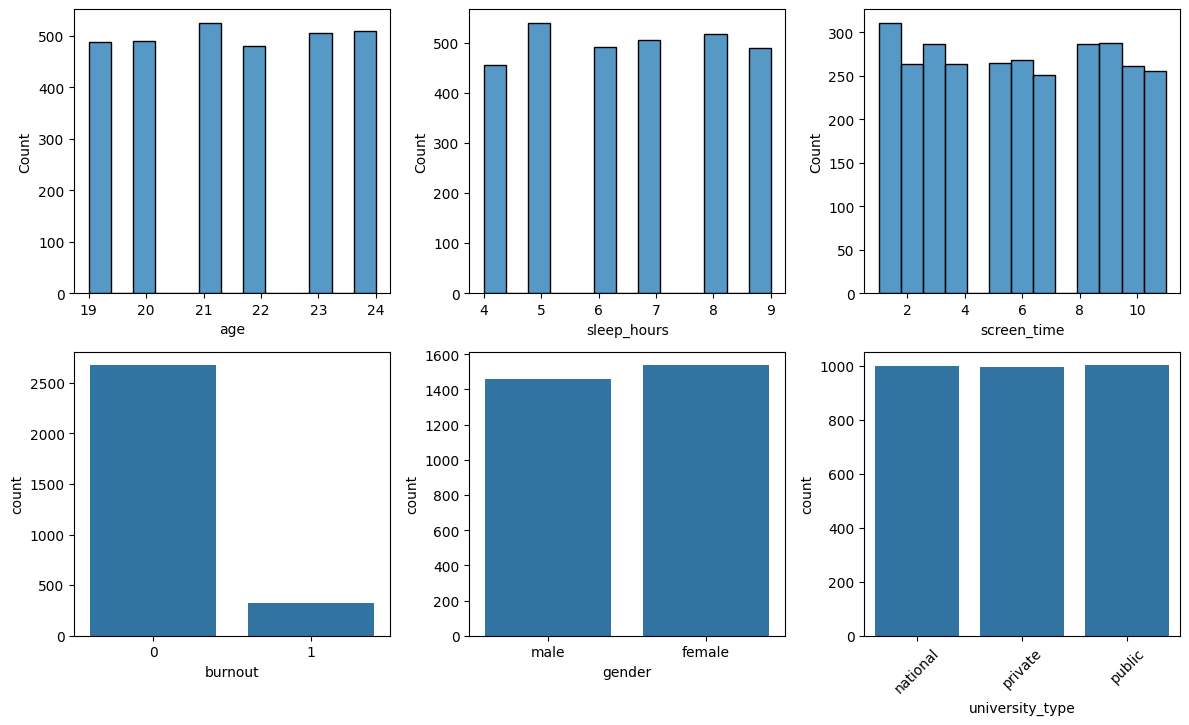

In [152]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

sns.histplot(df_clean["age"], ax=axes[0, 0])
sns.histplot(df_clean["sleep_hours"], ax=axes[0, 1])
sns.histplot(df_clean["screen_time"], ax=axes[0, 2])

sns.countplot(x="burnout", data=df_clean, ax=axes[1, 0])
sns.countplot(x="gender", data=df_clean, ax=axes[1, 1])
sns.countplot(x="university_type", data=df_clean, ax=axes[1, 2])

plt.tight_layout()
plt.xticks(rotation=45)

THe label (`burnout`) is imbalanced. We are lucky to have `class_weight='balanced'`.

> class_weight='balanced' modifies the loss function to penalize misclassifications of the minority class more heavily, while resampling alters the dataset itself by adding or removing samples before training.

<Axes: >

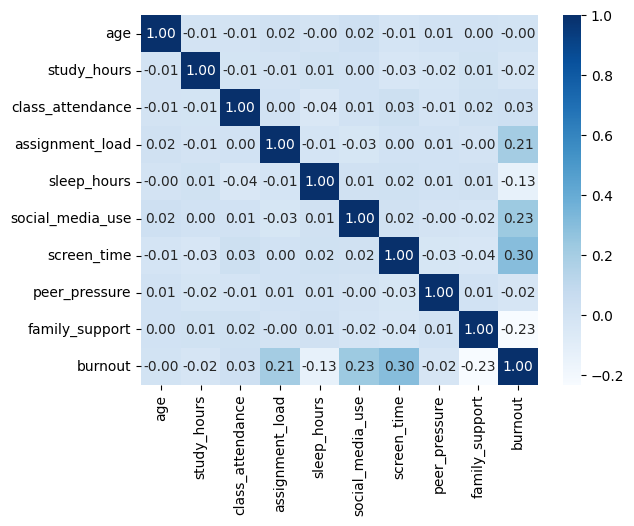

In [153]:
df_num = df_clean.select_dtypes(include=["number"])
sns.heatmap(df_num.corr(), annot=True, fmt=".2f", cmap="Blues")

The heatmap reveals that age has zero correlation with `burnout`, whereas variables like `study_hours`, `peer_pressure` and `class_attendance` have a very low linear correlation with burnout. However, human behavior is rarely strictly linear.

In [154]:
# Let's drop `age`
df_clean = df_clean.drop("age", axis=1)

In [155]:
from sklearn.model_selection import train_test_split


def train_test_dev_split(df, test_size=0.2, dev_size=0.25, random_state=1):
    df_full_train, df_test = train_test_split(
        df,
        test_size=test_size,
        random_state=random_state,
    )
    df_train, df_val = train_test_split(
        df_full_train,
        test_size=dev_size,
        random_state=random_state,
    )
    return df_train, df_val, df_test


df_train, df_val, df_test = train_test_dev_split(df_clean)

## Model training

In [156]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer()


def prepare_X_and_y(df, prefit=True):
    y = df["burnout"].values
    records = df.drop("burnout", axis=1).to_dict("records")

    if not prefit:
        X = dv.fit_transform(records)
    else:
        X = dv.transform(records)
    return X, y


X_train, y_train = prepare_X_and_y(df_train, prefit=False)
X_val, y_val = prepare_X_and_y(df_val)

### Let's start with a linear model first.

In [157]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score


def train_linear_model(X, y, C=1.0):
    model = LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=1,
        C=C,
    )
    model.fit(X, y)
    return model


model = train_linear_model(X_train, y_train)
y_pred = model.predict(X_val)
roc_auc_score(y_val, y_pred)

np.float64(0.8427141297691632)

Let's tune C

In [158]:
C = [0.01, 0.1, 0.3, 0.5, 0.7, 1.0]
for c in C:
    model = train_linear_model(X_train, y_train, C=c)
    y_pred = model.predict(X_val)
    score = roc_auc_score(y_val, y_pred)
    print(f"{c=} -> {round(score, 3)}")

c=0.01 -> 0.854
c=0.1 -> 0.845
c=0.3 -> 0.844
c=0.5 -> 0.844
c=0.7 -> 0.844
c=1.0 -> 0.843


`0.01` leads to a better model

Now let's try removing the features that got very low correlations with `burnout`

In [159]:
low_corr_feat = ["study_hours", "peer_pressure", "class_attendance"]

# Let's see if removing them to see if there are improvements
df_clean_2 = df_clean.drop(low_corr_feat, axis=1)

df_train_2, df_test_2, df_val_2 = train_test_dev_split(df_clean_2)
X_train_2, y_train_2 = prepare_X_and_y(df_train_2, prefit=False)
X_val_2, y_val_2 = prepare_X_and_y(df_val_2)

model_2 = train_linear_model(X_train_2, y_train_2, C=0.01)
y_pred_2 = model_2.predict(X_val_2)
round(roc_auc_score(y_val_2, y_pred_2), 3)

np.float64(0.862)

In [160]:
linear_model = model_2

Great! We passed from `0.854` to `0.862`

### It is time to try some tree models

#### RandomForest

In [161]:
X_train, y_train = prepare_X_and_y(df_train, prefit=False)

In [162]:
from sklearn.ensemble import RandomForestClassifier


def train_random_forest(
    X, y, n_estimators=100, max_depth=5, min_samples_leaf=1, random_state=1
):
    model = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        random_state=random_state,
        class_weight="balanced",
        n_jobs=-1,
    )
    model.fit(X, y)
    return model


model = train_random_forest(X_train, y_train)
y_pred = model.predict(X_val)
roc_auc_score(y_val, y_pred)

np.float64(0.7949759045767992)

Let's tune some parameters

In [163]:
max_depths = [4, 6, 8, 12, None]
min_samples_leafs = [2, 5, 10, 20]

scores = []
for max_depth in max_depths:
    for min_samples_leaf in min_samples_leafs:
        model = train_random_forest(
            X_train,
            y_train,
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
        )
        y_pred = model.predict(X_val)
        score = roc_auc_score(y_val, y_pred)
        scores.append((max_depth, min_samples_leaf, round(score, 3)))

<Axes: xlabel='min_samples_leaf', ylabel='max_depth'>

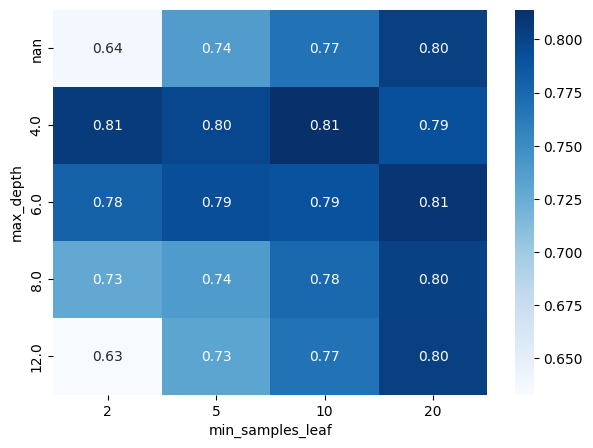

In [164]:
df_score = pd.DataFrame(scores, columns=["max_depth", "min_samples_leaf", "score"])
df_score = df_score.pivot(index="max_depth", columns="min_samples_leaf", values="score")

plt.figure(figsize=(7, 5))
sns.heatmap(df_score, annot=True, fmt=".2f", cmap="Blues")

The winners are (score: 0.81):
- `max_depth=4.0` and `min_samples_leaf=2`
- `max_depth=4.0` and `min_samples_leaf=10`
- `max_depth=6.0` and `min_samples_leaf=20`

Let's go with `max_depth=4.0` and `min_samples_leaf=10`

Now let's see where we can cap `n_estimators`

In [165]:
n_estimators = [10, 50, 75, 100, 200]

scores = []
for n_estimator in n_estimators:
    model = train_random_forest(
        X_train,
        y_train,
        n_estimators=n_estimator,
        max_depth=4,
        min_samples_leaf=10,
    )
    y_pred = model.predict(X_val)
    score = roc_auc_score(y_val, y_pred)
    scores.append((n_estimator, round(score, 3)))

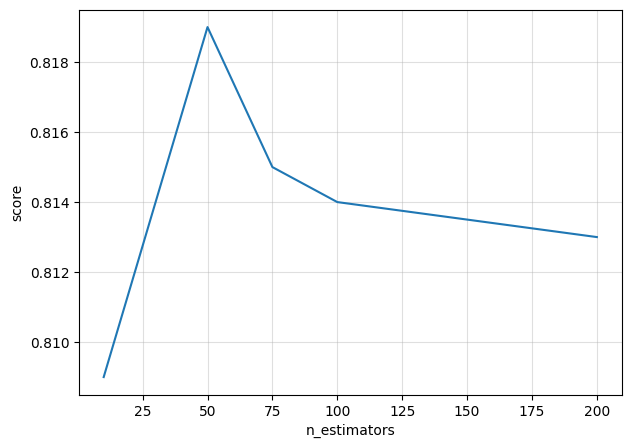

In [166]:
df_score = pd.DataFrame(scores, columns=["n_estimators", "score"])

plt.figure(figsize=(7, 5))
plt.plot(df_score["n_estimators"], df_score["score"])
plt.xlabel("n_estimators")
plt.ylabel("score")
plt.grid(True, alpha=0.4)

`50` gives the best score

In [167]:
rf_model = train_random_forest(
    X_train,
    y_train,
    n_estimators=50,
    max_depth=4,
    min_samples_leaf=10,
)
y_pred = rf_model.predict(X_val)
round(roc_auc_score(y_val, y_pred), 3)

np.float64(0.819)

In [168]:
feature_names = list(dv.get_feature_names_out())
importances = rf_model.feature_importances_
sorted_importances = importances.argsort()

print("Top 5 important features")
for i in sorted_importances[:5]:
    print(f"{feature_names[i]}: {importances[i]}")

Top 5 important features
gender=male: 0.0016974755969189294
tuition=Yes: 0.001846849762443285
tuition=No: 0.0019904924284466947
family_income_level=high: 0.002335896686599439
university_type=national: 0.003389598694890779


So far, the linear model gives better score than the random forest one (0.862 > 0.819)

#### Xgboost

In [169]:
pip install xgboost

In [170]:
import xgboost as xgb

dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=feature_names)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=feature_names)

In [171]:
xgb_params = {
    "objective": "binary:logistic",
    "min_child_weight": 1,
    "max_depth": 10,
    "eta": 0.1,
    "nthread": 8,
    "seed": 1,
    "verbosity": 1,
}

In [172]:
def train_xgboost(xgb_params, dtrain, evals=None):
    model = xgb.train(
        xgb_params,
        dtrain,
        num_boost_round=100,
        verbose_eval=5,
        evals=evals,
    )
    return model


model = train_xgboost(xgb_params, dtrain)
y_pred = model.predict(dval)
round(roc_auc_score(y_val, y_pred), 3)

np.float64(0.924)

The model is pretty good, let's see if we can get it an higher score

In [173]:
max_depths = [4, 6, 8, 12, None]
min_child_weights = [2, 5, 10, 20]

scores = []
for max_depth in max_depths:
    for min_child_weight in min_child_weights:
        xgb_params["max_depth"] = max_depth
        xgb_params["min_child_weight"] = min_child_weight

        model = train_xgboost(xgb_params, dtrain)
        y_pred = model.predict(dval)
        score = roc_auc_score(y_val, y_pred)
        scores.append((max_depth, min_child_weight, round(score, 3)))

<Axes: xlabel='min_child_weight', ylabel='max_depth'>

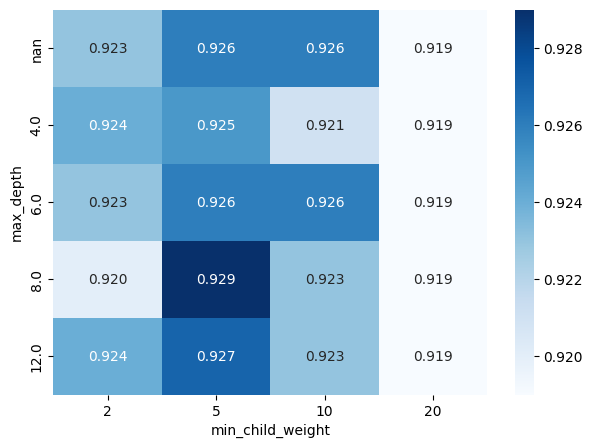

In [174]:
df_score = pd.DataFrame(scores, columns=["max_depth", "min_child_weight", "score"])
df_score = df_score.pivot(index="max_depth", columns="min_child_weight", values="score")

plt.figure(figsize=(7, 5))
sns.heatmap(df_score, annot=True, fmt=".3f", cmap="Blues")

`max_depth=8` and `min_child_weight=5` leads to slightly higher score

In [175]:
xgb_params["max_depth"] = 8
xgb_params["min_child_weight"] = 5

Now, let's see which Eta is best

In [176]:
%%capture output
watchlist = [(dtrain, "dtrain"), (dval, "dval")]
etas = [0.01, 0.1, 0.3, 0.5, 0.7, 1.0]

for eta in etas:
    xgb_params["eta"] = eta
    model = train_xgboost(xgb_params, dtrain, watchlist)
    model.predict(dval)
    print("SEPARATOR")

Let's convert the xgb ouput into df_scores

In [177]:
df_scores = []
for block in output.stdout.split("SEPARATOR"):
    block_stripped = block.strip()
    if not block_stripped:
        continue

    lines = pd.Series(block_stripped.split("\n"))
    records = lines.str.split("\t")

    df_score = pd.DataFrame.from_records(
        records,
        columns=("iter_num", "dtrain-logloss", "dval-logloss"),
    )
    df_score["iter_num"] = df_score["iter_num"].str.strip("[]").astype(int)
    df_score["dtrain-logloss"] = df_score["dtrain-logloss"].str.split(":").str[1].astype(float)
    df_score["dval-logloss"] = df_score["dval-logloss"].str.split(":").str[1].astype(float)

    df_scores.append(df_score)

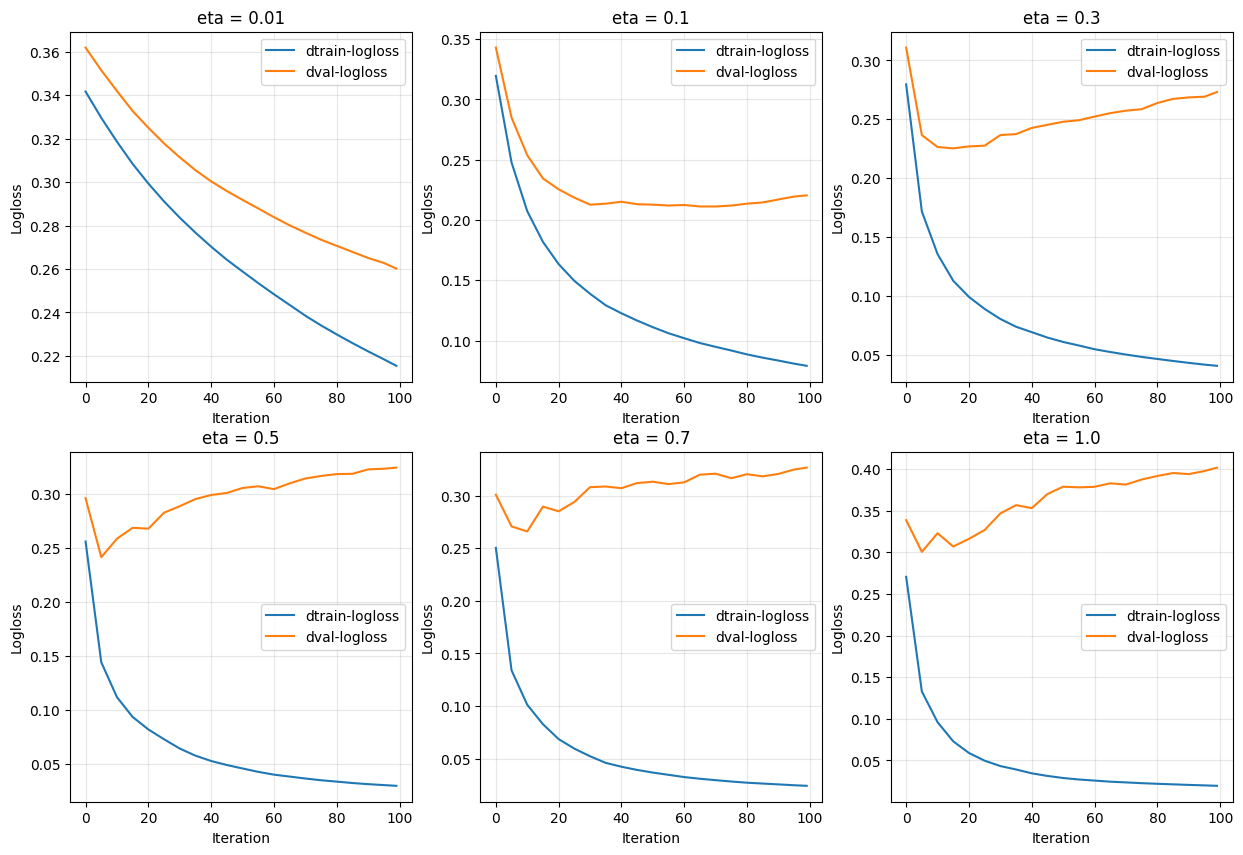

In [178]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for i, df_score in enumerate(df_scores):
    j, k = divmod(i, 3)
    ax = axes[j, k]

    iterations = df_score["iter_num"]
    train_loss = df_score["dtrain-logloss"]
    val_loss = df_score["dval-logloss"]

    ax.plot(iterations, train_loss, label="dtrain-logloss")
    ax.plot(iterations, val_loss, label="dval-logloss")
    ax.set_title(f"eta = {etas[i]}")
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Logloss")
    ax.legend()
    ax.grid(True, alpha=0.3)

`ETA=0.1` is the best

In [179]:
xgb_params["eta"] = 0.1
xgb_params

{'objective': 'binary:logistic',
 'min_child_weight': 5,
 'max_depth': 8,
 'eta': 0.1,
 'nthread': 8,
 'seed': 1,
 'verbosity': 1}

In [180]:
model = train_xgboost(xgb_params, dtrain)
y_pred = model.predict(dval)

print("roc_auc_score:", round(roc_auc_score(y_val, y_pred), 3))

roc_auc_score: 0.929


XGBoost outperforms the others: `0.929` > `0.862` > `0.819`

### Final model

In [181]:
X_full_train, y_full_train = prepare_X_and_y(pd.concat([df_train, df_val]), prefit=False)
X_test, y_test = prepare_X_and_y(df_val)

dtrain_full = xgb.DMatrix(X_full_train, label=y_full_train, feature_names=feature_names)
dtest = xgb.DMatrix(X_test, label=y_test, feature_names=feature_names)

Let's check for a better threshold

In [182]:
from sklearn.metrics import accuracy_score, f1_score, recall_score

model = train_xgboost(xgb_params, dtrain_full)

y_pred = model.predict(dtest)
y_pred_binary = (y_pred >= 0.5).astype(int)

print("roc_auc_score:", round(roc_auc_score(y_test, y_pred), 3))
print("accuracy_score:", round(accuracy_score(y_test, y_pred_binary), 3))
print("recall_score:", round(recall_score(y_test, y_pred_binary), 3))
print("f1_score:", round(f1_score(y_test, y_pred_binary), 3))

roc_auc_score: 0.997
accuracy_score: 0.98
recall_score: 0.873
f1_score: 0.912


In [183]:
import numpy as np

thresholds = np.linspace(0.01, 0.99, 100)
scores = []

for thresh in thresholds:
    y_pred_binary = (y_pred >= thresh).astype(int)
    auc_val = round(roc_auc_score(y_test, y_pred_binary), 3)
    f1_val = round(f1_score(y_test, y_pred_binary), 3)
    scores.append((thresh, auc_val, f1_val))

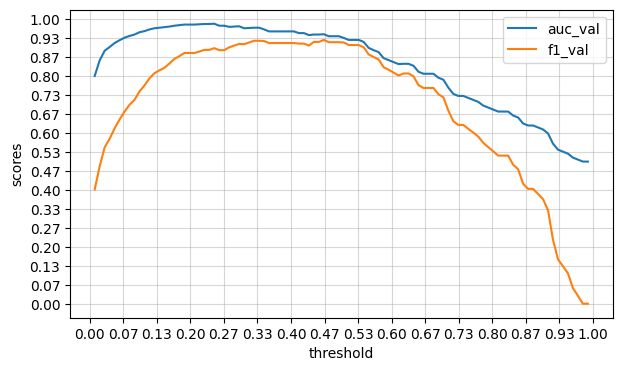

In [184]:
df_score = pd.DataFrame(scores, columns=("thresh", "auc_val", "f1_val"))

plt.figure(figsize=(7, 4))
plt.plot(df_score["thresh"], df_score["auc_val"], label="auc_val")
plt.plot(df_score["thresh"], df_score["f1_val"], label="f1_val")
plt.xlabel("threshold")
plt.ylabel("scores")

ticks_positions = [i / 15 for i in range(16)]
plt.xticks(ticks_positions, [f"{t:.2f}" for t in ticks_positions])
plt.yticks(ticks_positions, [f"{t:.2f}" for t in ticks_positions])

plt.legend()
plt.grid(True, alpha=0.5)

`0.465` is the best.

In [185]:
y_pred_binary = (y_pred >= 0.46).astype(int)

print("roc_auc_score:", round(roc_auc_score(y_test, y_pred), 3))
print("accuracy_score:", round(accuracy_score(y_test, y_pred_binary), 3))
print("recall_score:", round(recall_score(y_test, y_pred_binary), 3))
print("f1_score:", round(f1_score(y_test, y_pred_binary), 3))

roc_auc_score: 0.997
accuracy_score: 0.983
recall_score: 0.901
f1_score: 0.928


### Save the pipeline

In [186]:
import joblib
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

df_full_train = pd.concat([df_train, df_val])
records_full_train = df_full_train.drop("burnout", axis=1).to_dict("records")
y_full_train = df_full_train["burnout"].values

pipeline = Pipeline(
    [
        ("vectorizer", DictVectorizer(sparse=True)),
        ("classifier", XGBClassifier(**xgb_params, n_estimators=100)),
    ]
)

pipeline.fit(records_full_train, y_full_train)

# Save the entire pipeline
joblib.dump(pipeline, "pipeline.bin")

['pipeline.bin']